In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
raw_data=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\edgar_f\RawData_1E68_SEP_16_OCT_06.xlsx')
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 92869 entries, 0 to 92868
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  92869 non-null  str  
 1   Message  92869 non-null  str  
 2   Status   92869 non-null  str  
dtypes: str(3)
memory usage: 2.1 MB


In [16]:
aux=pd.DataFrame()
aux=raw_data
aux['Headers']='NaN'

for i in range(0,aux.shape[0]):
    aux.iloc[i,3]=aux.iloc[i,2][0:8]

aux['Headers'].value_counts()

Headers
0x252514    87746
0x252513     4969
0x252501       92
0x252511       62
Name: count, dtype: int64

In [17]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 92869 entries, 0 to 92868
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  92869 non-null  str  
 1   Message  92869 non-null  str  
 2   Status   92869 non-null  str  
 3   Headers  92869 non-null  str  
dtypes: str(4)
memory usage: 2.8 MB


Odometer

In [18]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux['Odometer in meters']=0.0
odometer=[]
date=[]
raw=[]
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    odometer.append(int(unit_aux.iloc[i,2][96:104],16))
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Odometer in meters']=odometer
unit_aux['Date']=date
unit_aux['Raw data']=raw

#print(unit_aux['Odometer in meters'])

unit=unit_aux.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 92715 entries, 55987 to 92864
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Created             92715 non-null  str  
 1   Message             92715 non-null  str  
 2   Status              92715 non-null  str  
 3   Headers             92715 non-null  str  
 4   Odometer in meters  92715 non-null  int64
 5   Date                92715 non-null  str  
 6   Raw data            92715 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.7 MB
None


000101000005 -> 0 -> 610836.0 -> 0x252514005906B50869487064444259003C38402D00000000EF00000000000061000000FFFFFFFFFFFFFFFFFFFF43800009521484000101000005CDCCF442EA3999C2DA24A840000000ED03852816FFFFFF00002FFFFFFFFFFF
000101000005 -> 1 -> 610836.0 -> 0x252514005907000869487064444259003C38402D00000000EF00000000000041000000FFFFFFFFFFFFFFFFFFFF42800009521485000101000005CDCCF442EA3999C2DA24A840000000ED03862826FFFFFF00002DFFFFFFFFFF
000101000006 -> 2 -> 611983.0 -> 0x2525140059583A0869487064444259003C38402D00000000F000000000000041000000FFFFFFFFFFFFFFFFFFFF42800009568F850001010000066666E942CB3999C2B823A8400000005D03862834FFFFFF000028FFFFFFFFFF
000101000007 -> 3 -> 610836.0 -> 0x252514005906B60869487064444259003C38402D00000000EF00000000000041000000FFFFFFFFFFFFFFFFFFFF42800009521484000101000007CDCCF442EA3999C2DA24A840000000ED03852819FFFFFF00002FFFFFFFFFFF
000101000008 -> 4 -> 610836.0 -> 0x252514005906B70869487064444259003C38402D00000000EF00000000000061000000FFFFFFFFFFFFFFFFFFFF4380000952148400010

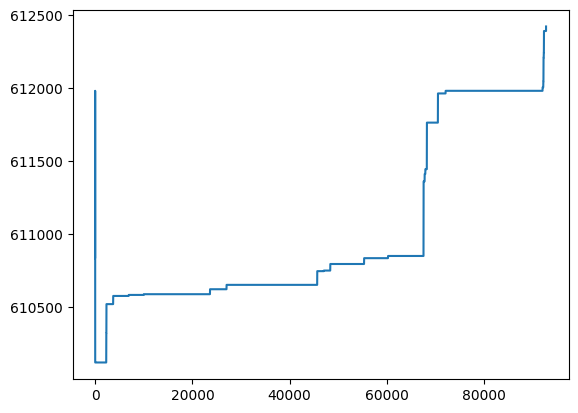

In [19]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,4]))
    x_axis.append(i)
    date.append(unit.iloc[i,5])
    raw_data_.append(unit.iloc[i,6])

#print("Delta odometer: ",y_axis[170]-y_axis[133],'meters')

for i in range(0,len(odometer)):
    print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

#print(odometer[len(odometer)-1]-odometer[0])
plt.plot(x_axis,y_axis)

Speed

In [20]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
#unit_aux['Odometer in meters']=0.0
speed=[]
date=[]
raw=[]
unit_speed=pd.DataFrame()
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    try:
        lbs_ind=(bin(int(unit_aux.iloc[i,2][50:52],16) & 64))
        if lbs_ind=='0b1000000':
            speed.append(int(unit_aux.iloc[i,2][142:145]))  
            date.append(unit_aux.iloc[i,2][106:118])
            raw.append(unit_aux.iloc[i,2])
            #print(lbs_ind)

    except:
        pass    

unit_speed['Speed']=speed
unit_speed['Date']=date
unit_speed['Raw data']=raw

unit=unit_speed.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 92708 entries, 57492 to 4968
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Speed     92708 non-null  int64
 1   Date      92708 non-null  str  
 2   Raw data  92708 non-null  str  
dtypes: int64(1), str(2)
memory usage: 2.8 MB
None


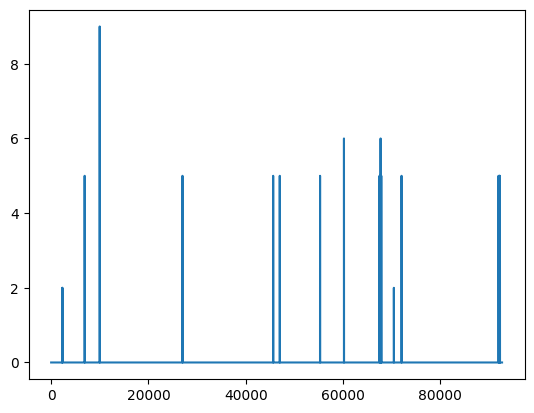

In [21]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,0]))
    x_axis.append(i)
    date.append(unit.iloc[i,1])
    raw_data_.append(unit.iloc[i,2])
    #print(raw_data_[i])

for i in range(0,len(speed)):
    if (y_axis[i]>55):
        print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

plt.plot(x_axis,y_axis)

Satellites

In [22]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
satellite_number=[]
satellite_connection_indicator=[]
date=[]
raw=[]
num_events=0

for i in range(0,unit_aux.shape[0]):
    satellite_number.append(int(unit_aux.iloc[i,2][50:52],16) & 31)
    satellite_connection_indicator.append(int(unit_aux.iloc[i,2][50:52],16) & 128)
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Satellites']=satellite_number
unit_aux['Satellite_connection_indicator']=satellite_connection_indicator
unit_aux['Raw data']=raw
unit_aux['date']=date

unit=unit_aux.sort_values('date',ascending=True)
unit.info()

for i in range(0,unit.shape[0]):
    if unit.iloc[i,4]<1:
        num_events=num_events+1
        print(unit.iloc[i,0], '->',unit.iloc[i,4],'->',unit.iloc[i,5],'->',unit.iloc[i,6])

print("Eventos históricos: ",num_events)

<class 'pandas.DataFrame'>
Index: 92715 entries, 55987 to 92864
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   Created                         92715 non-null  str  
 1   Message                         92715 non-null  str  
 2   Status                          92715 non-null  str  
 3   Headers                         92715 non-null  str  
 4   Satellites                      92715 non-null  int64
 5   Satellite_connection_indicator  92715 non-null  int64
 6   Raw data                        92715 non-null  str  
 7   date                            92715 non-null  str  
dtypes: int64(2), str(6)
memory usage: 6.4 MB
2026-09-26 00:41:21.656 -> 0 -> 128 -> 0x252514005906B80869487064444259003C38402D000000648000000000000041000000FFFFFFFFFFFFFFFFFFFF42C0000952148400010100001402DC00650E22C626000000000000000003852824FFFFFF00002CFFFFFFFFFF
2026-09-26 00:41:21.810 -> 0 -> 128 -> 0x2525140

In/Outs

15      14                 13      12      11      10      09      08       07 06 05 04 03 02 01 00
Power   Ignition/Input0    Input1  Input2  Input3  Input4  Input5  Input0

15=0, Connected
15=1. Disconnected

In [23]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux.info()
aux_cad=[]
aux_date=[]
aux_raw_data=[]
aux_input_number=[]
in_outs=[]

#unit_aux.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\concatenated.csv')

for i in range(0,unit_aux.shape[0]):
    long_cad=len(unit_aux.iloc[i,2])
    if ((long_cad>48) & (long_cad<204)):
        aux_cad.append(unit_aux.iloc[i,2])   

for i in range(0,len(aux_cad)):
    aux_value=aux_cad[i][64:68]
    aux_date.append(aux_cad[i][106:118])
    aux_raw_data.append(aux_cad[i])
    in_outs.append(bin (int (aux_cad[i][64:68],16)))      

unit_=pd.DataFrame()
unit_['in and outs']=in_outs
unit_['date']=aux_date
unit_['raw data']=aux_raw_data

in_outs_df=unit_.sort_values('date',ascending=True)

in_outs_df.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\edgar_f\in_outs_1E68_2.csv')

<class 'pandas.DataFrame'>
Index: 92715 entries, 0 to 92861
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  92715 non-null  str  
 1   Message  92715 non-null  str  
 2   Status   92715 non-null  str  
 3   Headers  92715 non-null  str  
dtypes: str(4)
memory usage: 3.5 MB


Ignition

In [24]:
in_outs_df.info()

for i in range(0,in_outs_df.shape[0]):
    length=len(in_outs_df.iloc[i,0])
    if length>16:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0])
    else:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0])

<class 'pandas.DataFrame'>
Index: 92715 entries, 57492 to 4968
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   in and outs  92715 non-null  str  
 1   date         92715 non-null  str  
 2   raw data     92715 non-null  str  
dtypes: str(3)
memory usage: 2.8 MB
Ignition On 0b110000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b110000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b110000100000000
Ignition On 0b100000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b100000100000000
Ignition On 0b110000100000000
Ignition On 0b100000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b100000100000000
Ignition On 0b110000100000000
Ignition On 0b100000100000000
Ignition On 0b110000100000000
Ignition On 0b100000100000000
Ignition 

Power

In [25]:
ext_bat_13=raw_data[raw_data['Status'].str.contains('0x252513')]
ext_bat_14=raw_data[raw_data['Status'].str.contains('0x252514')]
ext_bat_vol=pd.concat([ext_bat_13,ext_bat_14])
ext_bat=[]
date_bat=[]
bat_df=pd.DataFrame()

ext_bat_vol.info()

for i in range(0,ext_bat_vol.shape[0]):
    val=(float(ext_bat_vol.iloc[i,2][154:158]))/100
    date_bat.append(ext_bat_vol.iloc[i,2][106:119])
    ext_bat.append(val)
#print(ext_bat)

for i in range(0,ext_bat_vol.shape[0]):
    if ext_bat[i]<3:
        bat_df['Date']=date_bat
        bat_df['int_bat']=ext_bat

print(bat_df)

<class 'pandas.DataFrame'>
Index: 92715 entries, 0 to 92861
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  92715 non-null  str  
 1   Message  92715 non-null  str  
 2   Status   92715 non-null  str  
 3   Headers  92715 non-null  str  
dtypes: str(4)
memory usage: 3.5 MB
                Date  int_bat
0      2609160000309    28.17
1      2609160005319    28.25
2      2609160006319    28.31
3      2609160007319    28.30
4      2609160008319    28.32
...              ...      ...
92710  2610061543529    28.12
92711  2610061544009    28.13
92712  2610061544329    28.13
92713  2610061545129    28.12
92714  2610061546239    28.04

[92715 rows x 2 columns]


Pánico

In [ ]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux.info()
aux_cad=[]
aux_date=[]
aux_raw_data=[]
aux_input_number=[]

#unit_aux.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\concatenated.csv')

for i in range(0,unit_aux.shape[0]):
    long_cad=len(unit_aux.iloc[i,2])
    if ((long_cad>48) & (long_cad<204)):
        aux_cad.append(unit_aux.iloc[i,2])   

for i in range(0,len(aux_cad)):
    #aux_value=aux_cad[i][92:94]
    print(aux_value)
    aux_date.append(aux_cad[i][106:118])
    #aux_raw_data.append(aux_cad[i])
    if aux_value=='03':
        print(aux_value, ' -> ',aux_date[i])    

print("len aux_cad: ",len(aux_cad))

<class 'pandas.DataFrame'>
Index: 92715 entries, 0 to 92861
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  92715 non-null  str  
 1   Message  92715 non-null  str  
 2   Status   92715 non-null  str  
 3   Headers  92715 non-null  str  
dtypes: str(4)
memory usage: 3.5 MB
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00
00